# Can earnings-call language predict next-quarter EPS surprises?

CS 74 final project, Applied ML track. Aditya, AJ, Eric.

**Question.** A company holds an earnings call each quarter. Does the transcript of that call tell us whether the company's earnings per share (EPS) for the *next* quarter will come in well above analyst expectations (an **earnings beat**, label 1) or well below them (an **earnings miss**, label 0)?

**Data.** FinCall-Surprise: 2,688 earnings-call transcripts from 2019 to 2021, with a beat/miss label for each. We remove 2 duplicates, leaving 2,686 calls.

**Setup.** This is supervised binary classification. We split the calls by year into three disjoint sets:

| Set | Year | Used for |
|---|---|---|
| Training set | 2019 | fitting every model |
| Validation set | 2020 | hyperparameter tuning, model selection and choosing the decision threshold |
| Test set | 2021 | the final evaluation, done once |

**What this notebook does.**

1. Loads and cleans the data.
2. Defines how we evaluate models.
3. Scores a majority-class baseline.
4. Compares 20 text-processing setups for TF-IDF features, each with three classifiers, on the validation set.
5. Scores the chosen TF-IDF models on the test set.
6. Tests FinBERT features with two chunking methods and three feature sets.
7. Runs an error analysis to see what the models rely on.
8. Saves every table and figure to `results/`. The report reads from there.

**Run time.** About 6 minutes on an M4 MacBook once the FinBERT features are saved in `data/`. The very first run also scores every transcript chunk with FinBERT, which takes about 2 hours 45 minutes (much less with a CUDA GPU).

Shared helper functions (loading the data, splitting transcripts, building the TF-IDF pipelines) are in `helpers.py`.

In [1]:
import itertools
import json
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy import sparse, stats
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, accuracy_score,
                             average_precision_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, PredefinedSplit, TunedThresholdClassifierCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

from helpers import (CLASSIFIERS, DATA_DIR, RANDOM_SEED, RESULTS_DIR, TEST_YEAR, TRAIN_YEAR, VALIDATION_YEAR,
                     VIEWS, fit_chosen, load_data, make_pipeline, mask_company_names, positive_score,
                     remove_capitalized_words, setup_of, split_sections, term_weights)

RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 100)
notebook_start = time.time()

## 1. Data

Each record has a transcript, a label, and IDs for audio and slide files that we do not use. The dataset defines the surprise as reported EPS minus the analyst consensus, divided by the standard deviation of the analysts' forecasts. A surprise above +0.5 is labeled 1 (beat), below -0.5 is labeled 0 (miss), and calls in between are left out of the dataset. The files contain no EPS values, dates, tickers or sectors.

`load_data()` downloads the three JSON files from a pinned commit and removes two transcripts that appear twice (same text after lowercasing and collapsing whitespace). No transcript appears in more than one set.

In [2]:
data = load_data()
train, validation, test = (data[data.year == year].reset_index(drop=True)
                           for year in (TRAIN_YEAR, VALIDATION_YEAR, TEST_YEAR))

set_table = pd.DataFrame({
    "set": ["training", "validation", "test"],
    "year": [TRAIN_YEAR, VALIDATION_YEAR, TEST_YEAR],
    "calls": [len(frame) for frame in (train, validation, test)],
    "beats (label 1)": [int((frame.label == 1).sum()) for frame in (train, validation, test)],
    "misses (label 0)": [int((frame.label == 0).sum()) for frame in (train, validation, test)],
    "miss rate": [(frame.label == 0).mean() for frame in (train, validation, test)],
    "median words": [int(frame.words.median()) for frame in (train, validation, test)],
})
print("calls after removing duplicates:", len(data))
print("words per transcript: min %d, median %d, max %d" % (data.words.min(), data.words.median(), data.words.max()))
set_table

calls after removing duplicates: 2686
words per transcript: min 752, median 8778, max 57485


,set,year,calls,beats (label 1),misses (label 0),miss rate,median words
0,training,2019,919,731,188,0.205,8722
1,validation,2020,704,609,95,0.135,8859
2,test,2021,1063,942,121,0.114,8768


Misses are the minority class, and they get rarer every year (20.5% of the training set, 13.5% of the validation set, 11.4% of the test set). A model that always predicts "beat" would already be 88.6% accurate on the test set while never finding a single miss. That class imbalance is why we focus on finding misses, not on accuracy.

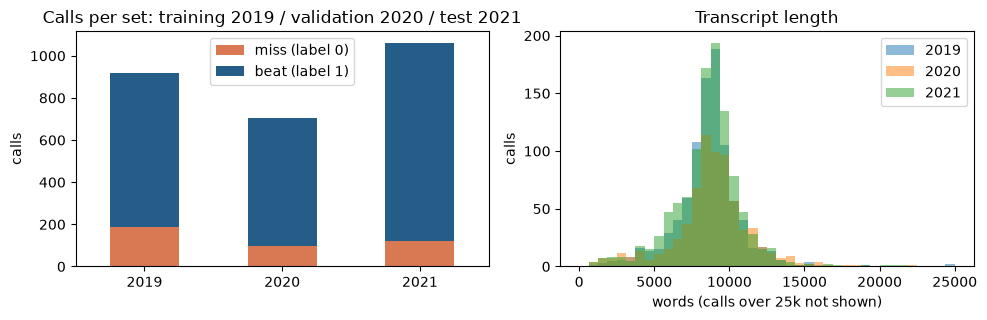

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
data.groupby(["year", "label"]).size().unstack().plot.bar(
    stacked=True, ax=axes[0], color=["#d97954", "#235d88"], rot=0)
axes[0].legend(["miss (label 0)", "beat (label 1)"])
axes[0].set(title="Calls per set: training 2019 / validation 2020 / test 2021", xlabel="", ylabel="calls")
for year in (TRAIN_YEAR, VALIDATION_YEAR, TEST_YEAR):
    axes[1].hist(data.words[data.year == year], bins=40, alpha=0.5, label=str(year), range=(0, 25000))
axes[1].set(title="Transcript length", xlabel="words (calls over 25k not shown)", ylabel="calls")
axes[1].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig_data.png", dpi=160)
plt.show()

### Transcript structure

Every speaker turn starts with a role tag such as `Executives:`, `Analysts:` or `Operator:`. We use the tags to split each call into **prepared remarks** (management's opening statement) and **Q&A** (which starts at the first analyst turn), and to separate what management says from what analysts ask. Operator turns ("our next question comes from...") carry no information, so we drop them.

In [4]:
example = data.text[0]
prepared, qa = split_sections(example)
print("Prepared remarks begin:\n ", prepared[0][1][:250], "...\n")
print("Q&A begins (%s):\n " % qa[0][0], qa[0][1][:250], "...\n")

sections = data.text.map(split_sections)
print("calls with no prepared remarks (they open with an analyst, e.g. conference chats):",
      sum(len(p) == 0 for p, _ in sections))
print("calls with no Q&A:", sum(len(q) == 0 for _, q in sections))

Prepared remarks begin:
  Thank you. Good morning, everybody, and thanks for joining our call today to discuss the combination of Bristol-Myers Squibb and Celgene. Joining me today are Giovanni Caforio, our Chairman and CEO; along with Charlie Bancroft, our CFO; as well as ma ...

Q&A begins (Analysts):
  I guess my question is a bigger picture one to start with here. Historically, large M&A in the group has had a very mixed track record. Just help us to understand why we should think about this deal [indiscernible]  As what other has got wrong and ho ...

calls with no prepared remarks (they open with an analyst, e.g. conference chats): 146
calls with no Q&A: 68


## 2. How we evaluate models

**The class we try to detect is a miss (label 0).** It is the rare class and the one an investor would want flagged. So in this notebook:

- a **true positive (TP)** is a miss that the model flags as a miss,
- a **false positive (FP)** is a beat that the model wrongly flags as a miss,
- a **false negative (FN)** is a miss that the model fails to flag.

From these, **precision** = TP / (TP + FP) (how many flagged calls really were misses) and **recall** = TP / (TP + FN) (how many of the misses we caught).

Metrics we report:

- **AP (average precision)**: the area under the precision-recall curve for misses. It summarizes how well the model *ranks* calls from most to least likely to miss, without picking a decision threshold. A model that ranks at random gets AP equal to the miss rate (0.135 on the validation set, 0.114 on the test set). This is the PR-AUC from our proposal.
- **Macro-F1**: the average of the F1 scores for beats and for misses.
- **Balanced accuracy**: the average of the recall for beats and the recall for misses.
- **AUC**: the area under the ROC curve.
- **Accuracy** and the **confusion matrix**.

**Model selection.** For every hyperparameter combination we fit the model on the training set and compute its AP on the validation set. We pick the combination with the highest validation AP. We select on AP, not macro-F1, because the validation set has only 95 misses and macro-F1 also depends on a decision threshold, which we would be tuning on the same small set.

**Decision threshold.** Each model outputs a score. A call is predicted as a miss when its score is below the decision threshold. The default threshold of 0.5 makes little sense here because the classes are imbalanced and the scores are not calibrated probabilities. So after picking the hyperparameters, we choose the threshold that maximizes macro-F1 on the validation set (`TunedThresholdClassifierCV`), without refitting the model.

**Why not k-fold cross-validation?** The class slides use k-fold cross-validation for model selection. Here, random folds would put 2020 and 2021 calls into the training folds and let the model learn from the future. We use one fixed validation set instead (`PredefinedSplit` inside `GridSearchCV`).

In [5]:
# AP for misses. pos_label=0 tells scikit-learn that a miss (label 0) is the class to detect.
negative_ap_scorer = make_scorer(average_precision_score, pos_label=0,
                                 response_method=("predict_proba", "decision_function"))


def choose_on_validation(model, grid, X_train, y_train, X_validation, y_validation):
    # Hyperparameter tuning: fit every combination in the grid on the training set and
    # score it on the validation set. Returns the best model (refit on the training set
    # only), its hyperparameters and a table of every trial.
    stack = sparse.vstack if sparse.issparse(X_train) else np.vstack
    split = PredefinedSplit(np.r_[np.full(len(y_train), -1), np.zeros(len(y_validation))])
    search = GridSearchCV(model, grid, cv=split, refit=False,
                          scoring={"ap_negative": negative_ap_scorer, "roc_auc": "roc_auc"})
    search.fit(stack([X_train, X_validation]), np.r_[y_train, y_validation])
    trials = pd.DataFrame(search.cv_results_["params"])
    trials["val_ap_negative"] = search.cv_results_["mean_test_ap_negative"]
    trials["val_roc_auc"] = search.cv_results_["mean_test_roc_auc"]
    trials["params"] = search.cv_results_["params"]
    best_params = search.cv_results_["params"][int(np.argmax(trials["val_ap_negative"]))]
    best_model = clone(model).set_params(**best_params).fit(X_train, y_train)
    return best_model, best_params, trials


def tune_threshold(fitted_model, X_validation, y_validation):
    # Choose the decision threshold that maximizes validation-set macro-F1 (the model is not refit).
    return TunedThresholdClassifierCV(fitted_model, scoring="f1_macro", cv="prefit",
                                      refit=False).fit(X_validation, y_validation)


def test_metrics(y, predicted, scores):
    # Classification quality on one set. Precision, recall and AP are for misses (label 0).
    return {
        "accuracy": accuracy_score(y, predicted),
        "macro_f1": f1_score(y, predicted, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y, predicted),
        "precision_negative": precision_score(y, predicted, pos_label=0, zero_division=0),
        "recall_negative": recall_score(y, predicted, pos_label=0),
        "ap_negative": average_precision_score(y, -np.asarray(scores), pos_label=0),
        "roc_auc": roc_auc_score(y, scores),
        "confusion_matrix": confusion_matrix(y, predicted, labels=[0, 1]).tolist(),
    }


def bootstrap_gain_over_majority(y, predicted):
    # 95% bootstrap confidence interval for macro-F1(model) - macro-F1(majority-class baseline).
    def gain(y, predicted):
        return (f1_score(y, predicted, average="macro", zero_division=0)
                - f1_score(y, np.ones_like(y), average="macro", zero_division=0))
    result = stats.bootstrap((np.asarray(y), np.asarray(predicted)), gain, paired=True, vectorized=False,
                             n_resamples=2000, method="percentile", random_state=RANDOM_SEED)
    return [float(result.confidence_interval.low), float(result.confidence_interval.high)]


def bootstrap_ap_sd(y, scores):
    # Bootstrap standard deviation of AP: how much AP moves just from resampling the calls.
    def ap(y, scores):
        return average_precision_score(y, -scores, pos_label=0)
    result = stats.bootstrap((np.asarray(y), np.asarray(scores)), ap, paired=True, vectorized=False,
                             n_resamples=2000, method="percentile", random_state=RANDOM_SEED)
    return float(result.standard_error)


test_results = []  # one row per model scored on the test set


def record_test(method, tuned_model, X_test, **extra):
    # Score a tuned model on the test set once and keep the row for the results table.
    scores = positive_score(tuned_model.estimator_, X_test)
    predicted = tuned_model.predict(X_test)
    test_results.append({"method": method, **extra, "val_macro_f1": tuned_model.best_score_,
                         "threshold": tuned_model.best_threshold_,
                         **{"test_" + k: v for k, v in test_metrics(test.label, predicted, scores).items()}})
    return scores, predicted

## 3. Majority-class baseline

The simplest model always predicts the majority class (a beat). Every other model has to beat this.

In [6]:
baseline = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(train), 1)), train.label)
X_dummy = np.zeros((len(test), 1))
test_results.append({"method": "majority-class baseline (always predicts beat)",
                     **{"test_" + k: v for k, v in test_metrics(
                         test.label, baseline.predict(X_dummy), positive_score(baseline, X_dummy)).items()}})
pd.DataFrame(test_results)[["method", "test_accuracy", "test_macro_f1", "test_recall_negative", "test_ap_negative"]]

,method,test_accuracy,test_macro_f1,test_recall_negative,test_ap_negative
0,majority-class baseline (always predicts beat),0.886,0.47,0.0,0.114


## 4. TF-IDF features: which text processing and which classifier work best?

**Features.** Each transcript becomes a bag-of-words feature vector: one TF-IDF weight for each n-gram in the vocabulary. TF-IDF gives a high weight to words that are frequent in this transcript but rare across transcripts. Fixed settings: lowercasing, accents removed, n-grams that appear in more than 95% of training-set calls dropped, sublinear term frequency (1 + log tf) and L2-normalized feature vectors. The vocabulary and IDF weights are learned from the training set only.

**Text processing compared (the TA asked us to compare these).** 5 views × 2 n-gram ranges × 2 number treatments = 20 setups:

- **view** of the transcript: `raw` (as released, with role tags and operator turns), `clean` (role tags and operator turns removed), `management` (only executives' turns), `prepared` (only prepared remarks), `qa` (only the Q&A)
- **n-grams**: unigrams only, or unigrams and bigrams
- **numbers**: kept, or every number replaced by the word "number"

All 20 use `min_df = 3` (a term must appear in at least 3 training-set calls) and a vocabulary of at most 60,000 terms. Section 4.2 then varies the vocabulary size.

**Classifiers and hyperparameter grids** (defined in `helpers.py`):

| Classifier | What it is | Hyperparameters tried |
|---|---|---|
| Logistic regression | sigmoid + cross-entropy cost, L2 regularization | C in {0.01, 0.1, 1, 10, 100, 1000} × class weight {none, balanced} |
| Linear SVC | soft-margin support vector classifier, linear kernel, hinge loss | C in {0.001, 0.01, 0.1, 1, 10} × class weight {none, balanced} |
| Multinomial naive Bayes | the text classifier from CS 74 HW4 | smoothing alpha in {0.001, 0.01, 0.1, 1} (alpha = 1 is Laplace smoothing) |

C is the inverse of the regularization strength λ, so a larger C means weaker regularization. "Balanced" class weights make each miss count about 4 times as much as a beat in the training cost.

That is 26 hyperparameter combinations per setup, or 520 fits across the 20 setups. For each setup we build the TF-IDF matrices once and then tune each classifier on them.

In [7]:
def search_setup(setup, train_frame, validation_frame, classifier_names=CLASSIFIERS):
    # Build the TF-IDF feature matrices for one setup, then tune each classifier on them.
    features = make_pipeline(setup, None)[:-1]  # the text-processing and TF-IDF steps only
    X_train = features.fit_transform(train_frame.text)
    X_validation = features.transform(validation_frame.text)
    tables = []
    for name in classifier_names:
        classifier, grid = CLASSIFIERS[name]
        _, _, trials = choose_on_validation(classifier, grid, X_train, train_frame.label,
                                            X_validation, validation_frame.label)
        tables.append(trials.assign(classifier=name, **setup))
    return pd.concat(tables, ignore_index=True)


setups = [{"view": view, "ngram": ngram, "numbers": numbers, "min_df": 3, "max_features": 60000}
          for view, ngram, numbers in itertools.product(VIEWS, [1, 2], ["kept", "masked"])]
trials = pd.concat([search_setup(setup, train, validation).assign(step="text")
                    for setup in tqdm(setups, desc="text-processing setups")], ignore_index=True)
print(len(trials), "fits")

# Best validation AP for each setup and classifier (best hyperparameters for each)
best_per_setup = (trials.groupby(["view", "ngram", "numbers", "classifier"]).val_ap_negative.max()
                  .unstack("classifier").reindex(VIEWS, level="view"))
best_per_setup

520 fits


classifier                linear SVC  logistic regression  naive Bayes
view       ngram numbers                                              
raw        1     kept          0.211                0.210        0.220
                 masked        0.209                0.208        0.217
           2     kept          0.205                0.206        0.200
                 masked        0.208                0.206        0.200
clean      1     kept          0.208                0.207        0.213
                 masked        0.206                0.205        0.209
           2     kept          0.204                0.203        0.197
                 masked        0.207                0.205        0.198
management 1     kept          0.209                0.208        0.208
                 masked        0.206                0.205        0.205
           2     kept          0.199                0.198        0.197
                 masked        0.203                0.202        0.198
prepared   1     kept          0.191                0.192        0.208
                 masked        0.190                0.190        0.206
           2     kept          0.198                0.199        0.210
                 masked        0.197                0.203        0.209
qa         1     kept          0.203                0.205        0.195
                 masked        0.202                0.202        0.196
           2     kept          0.203                0.200        0.193
                 masked        0.201                0.198        0.197

In [8]:
best_values = best_per_setup.stack()
by_ngram = best_values.unstack("ngram")
by_numbers = best_values.unstack("numbers")
best_row = trials.loc[trials.val_ap_negative.idxmax()]
print("validation AP across all 60 setup/classifier pairs: %.3f to %.3f (chance = %.3f)"
      % (best_values.min(), best_values.max(), (validation.label == 0).mean()))
print("best: %s, %s view, %d-gram, numbers %s -> %.3f"
      % (best_row.classifier, best_row["view"], best_row.ngram, best_row.numbers, best_row.val_ap_negative))
print("adding bigrams helped in %d of %d comparisons (largest gain %.3f, mean change %.3f)"
      % (((by_ngram[2] - by_ngram[1]) > 0).sum(), len(by_ngram), (by_ngram[2] - by_ngram[1]).max(),
         (by_ngram[2] - by_ngram[1]).mean()))
print("masking numbers changed AP by at most %.3f" % (by_numbers.masked - by_numbers.kept).abs().max())

validation AP across all 60 setup/classifier pairs: 0.190 to 0.220 (chance = 0.135)
best: naive Bayes, raw view, 1-gram, numbers kept -> 0.220
adding bigrams helped in 10 of 30 comparisons (largest gain 0.013, mean change -0.003)
masking numbers changed AP by at most 0.004


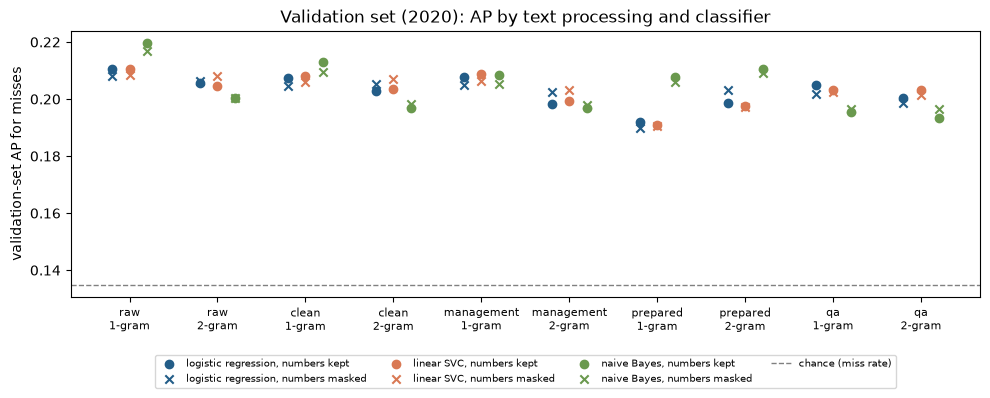

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
positions = np.arange(len(VIEWS) * 2)
for k, (name, color) in enumerate(zip(CLASSIFIERS, ["#235d88", "#d97954", "#6a994e"])):
    for numbers, marker in [("kept", "o"), ("masked", "x")]:
        values = [best_values[(view, ngram, numbers, name)] for view in VIEWS for ngram in (1, 2)]
        ax.scatter(positions + (k - 1) * 0.2, values, color=color, marker=marker,
                   label="%s, numbers %s" % (name, numbers))
ax.axhline((validation.label == 0).mean(), ls="--", c="gray", lw=1, label="chance (miss rate)")
ax.set_xticks(positions, ["%s\n%d-gram" % (view, ngram) for view in VIEWS for ngram in (1, 2)], fontsize=8)
ax.set(ylabel="validation-set AP for misses", title="Validation set (2020): AP by text processing and classifier")
ax.legend(fontsize=7, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig_text_processing.png", dpi=160)
plt.show()

**What we see.** Every setup and classifier lands between 0.190 and 0.220 validation AP, well above chance (0.135) but close to each other. Section 5 shows that resampling the validation calls alone moves AP by about 0.03 (one bootstrap standard deviation), so the whole spread is about one standard deviation: **the validation set cannot tell these text-processing choices apart.** Bigrams helped in only 10 of 30 comparisons, and masking numbers changed AP by at most 0.004. The best setup is naive Bayes on the raw transcript with unigrams and numbers kept, so the simplest text processing did as well as anything else.

### 4.2 Vocabulary size

For the best setup, we also vary `min_df` (3 or 10) and the vocabulary cap (10,000, 60,000 or no cap).

In [10]:
vocabulary_setups = [{"view": best_row["view"], "ngram": int(best_row.ngram), "numbers": best_row.numbers,
                      "min_df": min_df, "max_features": max_features}
                     for min_df, max_features in itertools.product([3, 10], [10000, 60000, None])
                     if (min_df, max_features) != (3, 60000)]
trials = pd.concat([trials] + [search_setup(setup, train, validation).assign(step="vocabulary")
                               for setup in tqdm(vocabulary_setups, desc="vocabulary sizes")], ignore_index=True)
best_setup_trials = trials[(trials["view"] == best_row["view"]) & (trials.ngram == best_row.ngram)
                           & (trials.numbers == best_row.numbers)]
(best_setup_trials.groupby(["min_df", "max_features", "classifier"], dropna=False).val_ap_negative.max()
 .unstack("classifier"))

classifier           linear SVC  logistic regression  naive Bayes
min_df max_features                                              
3      10000.0            0.206                0.204        0.204
       60000.0            0.211                0.210        0.220
       NaN                0.211                0.210        0.220
10     10000.0            0.207                0.207        0.215
       60000.0            0.207                0.206        0.214
       NaN                0.207                0.206        0.214

A smaller vocabulary cost at most 0.016 AP, so the default (`min_df = 3`, 60,000 terms) stays.

### 4.3 How hyperparameter tuning behaved

Validation AP for every hyperparameter combination on the best setup:

In [11]:
winning_setup = best_setup_trials[(best_setup_trials.min_df == 3) & (best_setup_trials.max_features == 60000)]
for name in CLASSIFIERS:
    rows = winning_setup[winning_setup.classifier == name]
    grid_columns = list(CLASSIFIERS[name][1])
    print(name)
    display(rows[grid_columns + ["val_ap_negative"]].fillna({"class_weight": "none"}).reset_index(drop=True))

logistic regression


,C,class_weight,val_ap_negative
0,0.01,none,0.174
1,0.01,balanced,0.190
2,0.10,none,0.192
3,0.10,balanced,0.191
4,1.00,none,0.200
5,1.00,balanced,0.202
6,10.00,none,0.208
7,10.00,balanced,0.208
8,100.00,none,0.210
9,100.00,balanced,0.210


linear SVC


,C,class_weight,val_ap_negative
0,0.001,none,0.173
1,0.001,balanced,0.190
2,0.010,none,0.192
3,0.010,balanced,0.192
4,0.100,none,0.202
5,0.100,balanced,0.200
6,1.000,none,0.211
7,1.000,balanced,0.208
8,10.000,none,0.210
9,10.000,balanced,0.210


naive Bayes


,alpha,val_ap_negative
0,0.001,0.220
1,0.010,0.216
2,0.100,0.203
3,1.000,0.173


For logistic regression and the SVC, AP rises as regularization gets weaker (larger C) and then levels off. We might have expected strong regularization to help against overfitting, since there are only 919 training calls and about 20,000 features, but small C did worse. Naive Bayes did best with the least smoothing (alpha = 0.001). That is the edge of its grid, but AP is already flattening (0.216 at 0.01, 0.220 at 0.001), so going smaller would change little. Balanced class weights barely changed AP, because tuning the decision threshold afterwards does most of what reweighting the cost would.

## 5. Test-set results for the TF-IDF models

**Model selection.** For each classifier we keep the setup and hyperparameters with the best validation AP. The model with the best validation AP overall is our **validation-set winner**. Each chosen model is refit on the training set, its decision threshold is tuned on the validation set, and then it is scored on the test set once. We also score the winning classifier's best model for each view, to see whether the text-processing ranking holds on the test set.

In [12]:
def fit_final(row, train_frame, validation_frame):
    # Refit a chosen setting on the training set and tune its decision threshold on the validation set.
    return tune_threshold(fit_chosen(row, train_frame), validation_frame.text, validation_frame.label)


def settings_of(row):
    return {**setup_of(row), "classifier": row["classifier"], "params": json.dumps(row["params"])}


trials["max_features"] = trials["max_features"].astype(object).where(trials["max_features"].notna(), None)
chosen = {"TF-IDF + " + name: trials.loc[trials[trials.classifier == name].val_ap_negative.idxmax()]
          for name in CLASSIFIERS}
winner_name = max(chosen, key=lambda name: chosen[name].val_ap_negative)
winner = chosen[winner_name]
for view in VIEWS:
    rows = trials[(trials.classifier == winner.classifier) & (trials["view"] == view)]
    chosen["%s, view = %s" % (winner.classifier, view)] = rows.loc[rows.val_ap_negative.idxmax()]

models, test_scores, test_predictions = {}, {}, {}
for name, row in tqdm(chosen.items(), desc="final models"):
    models[name] = fit_final(row, train, validation)
    test_scores[name], test_predictions[name] = record_test(name, models[name], test.text,
                                                            val_ap_negative=row.val_ap_negative, **settings_of(row))

print("validation-set winner:", winner_name)
columns = ["method", "view", "ngram", "numbers", "params", "threshold", "val_ap_negative", "test_accuracy",
           "test_macro_f1", "test_balanced_accuracy", "test_precision_negative", "test_recall_negative",
           "test_ap_negative", "test_roc_auc", "test_confusion_matrix"]
pd.DataFrame(test_results)[columns]

validation-set winner: TF-IDF + naive Bayes


,method,view,ngram,numbers,params,threshold,val_ap_negative,test_accuracy,test_macro_f1,test_balanced_accuracy,test_precision_negative,test_recall_negative,test_ap_negative,test_roc_auc,test_confusion_matrix
0,majority-class baseline (always predicts beat),NaN,NaN,NaN,NaN,NaN,NaN,0.886,0.470,0.500,0.000,0.000,0.114,0.500,"[[0, 121], [0, 942]]"
1,TF-IDF + logistic regression,raw,1.0,kept,"{""C"": 100, ""class_weight"": null}",0.872,0.210,0.689,0.526,0.587,0.172,0.455,0.172,0.605,"[[55, 66], [265, 677]]"
2,TF-IDF + linear SVC,raw,1.0,kept,"{""C"": 1, ""class_weight"": null}",0.312,0.211,0.780,0.553,0.570,0.195,0.298,0.183,0.614,"[[36, 85], [149, 793]]"
3,TF-IDF + naive Bayes,raw,1.0,kept,"{""alpha"": 0.001}",0.838,0.220,0.796,0.547,0.553,0.188,0.240,0.197,0.627,"[[29, 92], [125, 817]]"
4,"naive Bayes, view = raw",raw,1.0,kept,"{""alpha"": 0.001}",0.838,0.220,0.796,0.547,0.553,0.188,0.240,0.197,0.627,"[[29, 92], [125, 817]]"
5,"naive Bayes, view = clean",clean,1.0,kept,"{""alpha"": 0.001}",0.838,0.213,0.802,0.551,0.557,0.196,0.240,0.200,0.629,"[[29, 92], [119, 823]]"
6,"naive Bayes, view = management",management,1.0,kept,"{""alpha"": 0.01}",0.778,0.208,0.771,0.556,0.579,0.198,0.331,0.208,0.638,"[[40, 81], [162, 780]]"
7,"naive Bayes, view = prepared",prepared,2.0,kept,"{""alpha"": 0.01}",0.727,0.210,0.802,0.554,0.560,0.200,0.248,0.208,0.650,"[[30, 91], [120, 822]]"
8,"naive Bayes, view = qa",qa,2.0,masked,"{""alpha"": 0.01}",0.775,0.197,0.847,0.568,0.561,0.261,0.190,0.216,0.628,"[[23, 98], [65, 877]]"


95% bootstrap confidence interval for the winner's macro-F1 gain over the baseline: [+0.042, +0.114]
bootstrap standard deviation of the winner's validation AP: 0.032


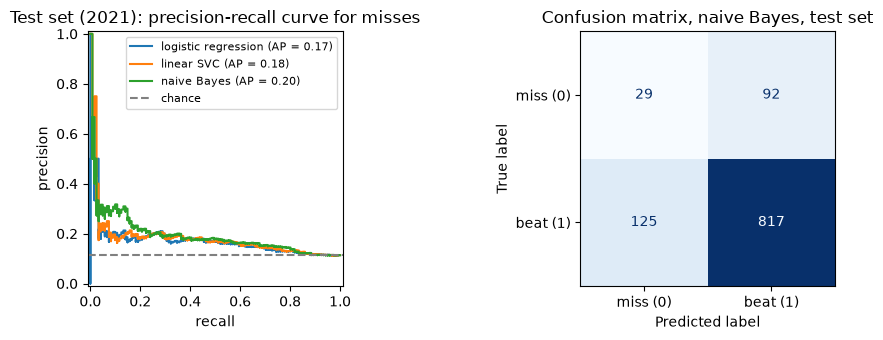

In [13]:
winner_scores, winner_predictions = test_scores[winner_name], test_predictions[winner_name]
gain_ci = bootstrap_gain_over_majority(test.label, winner_predictions)
winner_validation_scores = positive_score(models[winner_name].estimator_, validation.text)
val_ap_sd = bootstrap_ap_sd(validation.label, winner_validation_scores)
print("95%% bootstrap confidence interval for the winner's macro-F1 gain over the baseline: [%+.3f, %+.3f]" % tuple(gain_ci))
print("bootstrap standard deviation of the winner's validation AP: %.3f" % val_ap_sd)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name in CLASSIFIERS:
    PrecisionRecallDisplay.from_predictions(test.label, -test_scores["TF-IDF + " + name], pos_label=0,
                                            name=name, ax=axes[0])
axes[0].axhline((test.label == 0).mean(), ls="--", c="gray", label="chance")
axes[0].set(title="Test set (2021): precision-recall curve for misses", xlabel="recall", ylabel="precision")
axes[0].legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(test.label, winner_predictions, display_labels=["miss (0)", "beat (1)"],
                                        cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set(title="Confusion matrix, %s, test set" % winner_name.replace("TF-IDF + ", ""))
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig_test.png", dpi=160)
plt.show()

**What we see.**

- All three TF-IDF models beat the majority-class baseline on AP, AUC and macro-F1, and the bootstrap confidence interval for naive Bayes' macro-F1 gain is above zero. So the text carries real signal.
- The signal is weak. Naive Bayes flags 154 calls as misses, of which 29 are real (precision 0.19), and it catches 29 of the 121 misses (recall 0.24).
- Logistic regression's tuned threshold is more aggressive. It catches more misses (recall 0.45), but with many more false positives (265).
- Every model is less accurate than the baseline. That is the price of flagging any misses when 89% of calls are beats.
- The validation-set ranking holds on the test set (naive Bayes, then SVC, then logistic regression on AP), but AP dropped from the validation set to the test set for every model, partly because misses are rarer in 2021.
- On the test set, the five views reshuffle: the Q&A view does best (AP 0.216) and the raw view, which won on the validation set, does worst (0.197). This confirms that the text-processing gaps are noise.

## 6. FinBERT features

FinBERT (`ProsusAI/finbert`) is BERT-base fine-tuned to label financial sentences as positive, negative or neutral. We keep its weights frozen and only use it to create features, so it is never trained on our labels. FinBERT reads at most 512 tokens, but a median call has about 11,000, so **how we cut each call into chunks matters**. Following the TA's feedback, we compare two chunking methods at opposite ends of the chunk-size range:

| Chunking | One chunk is |
|---|---|
| `sentence` | one sentence (split at `.`, `!` or `?`). Sentences under 4 words are dropped, and longer sentences are cut at 128 tokens. This matches how FinBERT was trained. |
| `512` | a window of 510 consecutive tokens plus the `[CLS]` and `[SEP]` tokens, which is BERT's maximum input. Windows do not overlap, so no text is counted twice. |

We score every chunk of every call. Before chunking we drop role tags and operator turns, and no chunk crosses from the prepared remarks into the Q&A.

For each chunk we keep FinBERT's three sentiment probabilities and a dense **embedding**: the average of FinBERT's last hidden layer over the chunk's tokens (mean pooling). Each call then gets three feature vectors, each averaging over chunks weighted by their length in tokens:

- `mean3`: the average positive, negative and neutral probability (3 features). This was the plan in our proposal.
- `stats`: 21 sentiment summary features (mean probabilities, the mean and spread of positive minus negative, and the share of chunks labeled positive and negative), computed for the whole call, the prepared remarks and the Q&A.
- `embed`: the average 768-dimensional embedding.

Each feature vector is standardized (feature scaling to mean 0 and standard deviation 1) and fed to an L2-regularized logistic regression, tuned on the validation set with C in {0.001, 0.01, 0.1, 1, 10} × class weight {none, balanced}.

Scoring every chunk is slow (1 hour 44 minutes for sentence chunks and 58 minutes for 512-token windows on an M4 MacBook), so the features are saved to `data/finbert_<chunking>.npz` and reused on later runs. Inference runs in half precision on the GPU; on a sample of calls, the probabilities moved by at most 0.0013 compared with full precision. A third method with 128-token windows was planned but dropped because each pass took one to two hours.

In [14]:
MODEL_NAME = "ProsusAI/finbert"
MODEL_REVISION = "0bc2ac10dda6929bcb1f77ccc43c7ec5c424f031"
MAX_TOKENS = {"sentence": 128, "512": 512}  # per chunk, including [CLS] and [SEP]
BATCH_SIZE = {"sentence": 128, "512": 32}
SENTENCE_END = re.compile(r"(?<=[.!?])\s+")


def chunk_call(text, tokenizer, chunking):
    # Return (section, token ids) for every chunk; section 0 = prepared remarks, 1 = Q&A.
    chunks = []
    for section, turns in enumerate(split_sections(text)):
        if chunking == "sentence":
            sentences = [sentence for _, turn in turns for sentence in SENTENCE_END.split(turn)
                         if len(sentence.split()) >= 4]
            if sentences:
                ids = tokenizer(sentences, max_length=MAX_TOKENS["sentence"], truncation=True)["input_ids"]
                chunks += [(section, chunk) for chunk in ids]
        elif turns:
            # return_overflowing_tokens cuts one long text into consecutive 512-token windows
            ids = tokenizer(" ".join(turn for _, turn in turns), max_length=MAX_TOKENS["512"], truncation=True,
                            return_overflowing_tokens=True, stride=0)["input_ids"]
            chunks += [(section, chunk) for chunk in ids]
    return chunks


def mean_token_pool(hidden, attention_mask):
    mask = attention_mask.unsqueeze(-1).to(hidden.dtype)
    return (hidden * mask).sum(dim=1) / mask.sum(dim=1)


def call_features(probabilities, embeddings, tokens, sections):
    # Turn one call's chunk outputs into the three feature vectors (chunks weighted by token count).
    positive, negative, neutral = probabilities.T
    net = positive - negative
    label = probabilities.argmax(axis=1)  # 0 positive, 1 negative, 2 neutral
    stats_features = []
    for keep in (sections >= 0, sections == 0, sections == 1):  # whole call, prepared remarks, Q&A
        if not keep.any():  # no prepared remarks or no Q&A: use the whole call
            keep = sections >= 0
        weights = tokens[keep]
        stats_features += [np.average(positive[keep], weights=weights), np.average(negative[keep], weights=weights),
                           np.average(neutral[keep], weights=weights), np.average(net[keep], weights=weights),
                           net[keep].std(), (label[keep] == 1).mean(), (label[keep] == 0).mean()]
    return {"mean3": np.average(probabilities, axis=0, weights=tokens), "stats": np.array(stats_features),
            "embed": np.average(embeddings, axis=0, weights=tokens)}


def extract_finbert_features(chunking):
    # Score every chunk of every call with FinBERT and save the feature vectors (slow: run once).
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, revision=MODEL_REVISION)
    model = model.to(device, torch.float32 if device == "cpu" else torch.float16).eval()
    assert [model.config.id2label[i].lower() for i in range(3)] == ["positive", "negative", "neutral"]

    features, tokens_per_chunk = {"mean3": [], "stats": [], "embed": []}, []
    for text in tqdm(data.text, desc="FinBERT " + chunking):
        chunks = chunk_call(text, tokenizer, chunking)
        order = np.argsort([len(ids) for _, ids in chunks])  # similar lengths in a batch means less padding
        probabilities = np.zeros((len(chunks), 3), np.float32)
        embeddings = np.zeros((len(chunks), 768), np.float32)
        for start in range(0, len(chunks), BATCH_SIZE[chunking]):
            batch = order[start:start + BATCH_SIZE[chunking]]
            # Padding to a multiple of 32 keeps the number of tensor shapes small (faster on Apple GPUs).
            inputs = tokenizer.pad({"input_ids": [chunks[i][1] for i in batch]}, pad_to_multiple_of=32,
                                   return_tensors="pt").to(device)
            with torch.inference_mode():
                output = model(**inputs, output_hidden_states=True)
            probabilities[batch] = output.logits.float().softmax(dim=-1).cpu().numpy()
            embeddings[batch] = mean_token_pool(output.hidden_states[-1].float(),
                                                inputs["attention_mask"]).cpu().numpy()
        tokens = np.array([len(ids) - 2 for _, ids in chunks])  # without [CLS] and [SEP]
        sections = np.array([section for section, _ in chunks])
        for name, value in call_features(probabilities, embeddings, tokens, sections).items():
            features[name].append(value)
        tokens_per_chunk.append(tokens)
    np.savez(DATA_DIR / ("finbert_%s.npz" % chunking), call_id=data.call_id.to_numpy(dtype=str),
             chunks_per_call=[len(tokens) for tokens in tokens_per_chunk],
             tokens_per_chunk=np.concatenate(tokens_per_chunk),
             **{name: np.stack(values) for name, values in features.items()})


finbert = {}
for chunking in MAX_TOKENS:
    path = DATA_DIR / ("finbert_%s.npz" % chunking)
    if not path.exists():
        extract_finbert_features(chunking)
    finbert[chunking] = np.load(path)
    assert (finbert[chunking]["call_id"] == data.call_id.to_numpy(dtype=str)).all()

chunk_table = pd.DataFrame([{
    "chunking": chunking,
    "median tokens per chunk": int(np.median(saved["tokens_per_chunk"])),
    "median chunks per call": int(np.median(saved["chunks_per_call"])),
    "total chunks": len(saved["tokens_per_chunk"]),
} for chunking, saved in finbert.items()])
chunk_table

,chunking,median tokens per chunk,median chunks per call,total chunks
0,sentence,22,433,1170088
1,512,510,22,58820


In [15]:
in_train, in_validation, in_test = ((data.year == year).to_numpy() for year in (TRAIN_YEAR, VALIDATION_YEAR, TEST_YEAR))
y = data.label.to_numpy()
finbert_model = Pipeline([("scaler", StandardScaler()),
                          ("classifier", LogisticRegression(max_iter=5000, random_state=RANDOM_SEED))])
finbert_grid = {"classifier__C": [0.001, 0.01, 0.1, 1, 10], "classifier__class_weight": [None, "balanced"]}

finbert_trials, finbert_rows = [], []
for chunking, saved in finbert.items():
    chunk_info = chunk_table.set_index("chunking").loc[chunking]
    for features in ("mean3", "stats", "embed"):
        X = saved[features]
        fitted, params, trials_here = choose_on_validation(finbert_model, finbert_grid, X[in_train], y[in_train],
                                                           X[in_validation], y[in_validation])
        finbert_trials.append(trials_here.assign(chunking=chunking, features=features))
        tuned = tune_threshold(fitted, X[in_validation], y[in_validation])
        method = "FinBERT %s / %s" % (chunking, features)
        record_test(method, tuned, X[in_test], chunking=chunking, features=features, params=json.dumps(params),
                    val_ap_negative=trials_here.val_ap_negative.max(),
                    val_ap_negative_sd=bootstrap_ap_sd(y[in_validation], positive_score(fitted, X[in_validation])),
                    median_tokens_per_chunk=chunk_info["median tokens per chunk"],
                    median_chunks_per_call=chunk_info["median chunks per call"],
                    total_chunks=chunk_info["total chunks"])
        finbert_rows.append(method)

finbert_table = pd.DataFrame(test_results).set_index("method").loc[finbert_rows]
finbert_table[["params", "val_ap_negative", "val_ap_negative_sd", "test_ap_negative", "test_roc_auc",
               "test_macro_f1", "test_recall_negative"]]

,params,val_ap_negative,val_ap_negative_sd,test_ap_negative,test_roc_auc,test_macro_f1,test_recall_negative
method,,,,,,,
FinBERT sentence / mean3,"{""classifier__C"": 1, ""classifier__class_weight"": ""balanced""}",0.118,0.015,0.110,0.465,0.484,0.025
FinBERT sentence / stats,"{""classifier__C"": 10, ""classifier__class_weight"": ""balanced""}",0.135,0.018,0.118,0.513,0.492,0.041
FinBERT sentence / embed,"{""classifier__C"": 0.1, ""classifier__class_weight"": ""balanced""}",0.207,0.034,0.168,0.580,0.547,0.281
FinBERT 512 / mean3,"{""classifier__C"": 0.001, ""classifier__class_weight"": null}",0.122,0.015,0.089,0.385,0.447,0.165
FinBERT 512 / stats,"{""classifier__C"": 10, ""classifier__class_weight"": null}",0.154,0.023,0.103,0.465,0.480,0.207
FinBERT 512 / embed,"{""classifier__C"": 0.001, ""classifier__class_weight"": ""balanced""}",0.184,0.028,0.188,0.624,0.572,0.331


**What we see.**

- **Sentiment alone carries no signal.** `mean3`, the averaged sentiment our proposal planned to use, scores *below* chance on the validation set with both chunking methods (0.118 and 0.122 against 0.135), and its test-set AUC is under 0.5. The 21 `stats` features do a little better on the validation set but fall back to chance on the test set.
- **Only the embeddings beat chance on both sets.** The sentence embeddings won on the validation set (0.207 against 0.184 for the 512-token windows), so they are our FinBERT choice. The 512-token windows did better on the test set (AP 0.188 against 0.168). The validation gap is smaller than one bootstrap standard deviation and the order flips on the test set, so **neither chunking method is clearly better**. We did not switch our choice after seeing the test set.
- **FinBERT does not beat TF-IDF.** The embeddings land in the same range as TF-IDF on the validation set (0.207 against 0.190 to 0.220) and do not beat naive Bayes on AP on either set.
- A plausible reason the embeddings work and sentiment does not: a mean-pooled embedding also captures what a passage is *about*, so like TF-IDF it can pick up the industry. The sentiment head reduces each passage to its tone.

## 7. Error analysis: what do the models rely on?

### 7.1 Feature analysis

Which terms push the winning model (naive Bayes) most strongly toward a miss or a beat?

In [16]:
winner_pipeline = models[winner_name].estimator_
prepare_step, tfidf_step, classifier_step = (winner_pipeline.named_steps[step]
                                             for step in ("prepare", "tfidf", "classifier"))
terms = tfidf_step.get_feature_names_out()
weights = term_weights(classifier_step)
order = np.argsort(weights)
pd.DataFrame({"toward a miss": terms[order[:20]], "toward a beat": terms[order[::-1][:20]]})

,toward a miss,toward a beat
0,targa,dram
1,mgp,paypal
2,fitments,biologics
3,pgp,jet
4,agi,foundry
5,badlands,biotech
6,interlayers,toni
7,perrysburg,shannon
8,tristan,gts
9,firstsolar,ebay


The terms pushing toward a miss are almost all **company names**: targa, mgp and pgp, badlands, firstsolar, and mandalay, murren and hornbuckle (MGM's resorts and executives). The terms pushing toward a beat describe **sectors**: dram, foundry and nanometer (chips), paypal and ebay (payments), biologics, biotech and tumor. Companies appear in more than one year, so a model can learn "this company or industry missed in 2019" without reading anything about how the quarter is going.

### 7.2 The most confident mistakes

The four most confident false negatives (misses predicted as beats) and false positives (beats predicted as misses), meaning the ones whose scores are furthest from the decision threshold, and the terms that pushed each prediction most:

In [17]:
errors = []
distance = np.abs(winner_scores - models[winner_name].best_threshold_)
for kind, wrong in [("false negative (miss predicted as beat)", (test.label == 0) & (winner_predictions == 1)),
                    ("false positive (beat predicted as miss)", (test.label == 1) & (winner_predictions == 0))]:
    wrong = wrong.to_numpy()
    for i in np.flatnonzero(wrong)[np.argsort(-distance[wrong])][:4]:
        contributions = tfidf_step.transform(prepare_step.transform([test.text[i]])).multiply(weights).toarray()[0]
        biggest = np.argsort(-np.abs(contributions))[:6]
        errors.append({"type": kind, "call_id": test.call_id[i], "words": int(test.words[i]),
                       "opening": " ".join(test.text[i].split()[:18]),
                       "top_terms": [[terms[j], round(float(contributions[j]), 4)] for j in biggest]})
pd.DataFrame([{**e, "top_terms": ", ".join(t for t, _ in e["top_terms"])} for e in errors])

,type,call_id,words,opening,top_terms
0,false negative (miss predicted as beat),2168436,5983,"Analysts: All right. Hello, everyone. Greetings from the virtual JPMorgan Healthcare Conference....","amg, asthma, murdo, amgen, tezepelumab, repatha"
1,false negative (miss predicted as beat),2360770,13759,"Operator: Ladies and gentlemen, thank you for standing by, and welcome to Lilly's Q2 Earnings Ca...","lilly, amyloid, verzenio, alzheimer, tau, trulicity"
2,false negative (miss predicted as beat),2169258,6776,"Analysts: Good morning, everybody. I'm Chris Schott at JPMorgan. And it's my pleasure to be host...","tau, glp, amyloid, obesity, alzheimer, trulicity"
3,false negative (miss predicted as beat),2416659,11197,"Operator: Hello, and welcome to the ResMed First Quarter Fiscal 2022 Earnings Conference Call an...","resmed, mick, apnea, masks, mask, brightree"
4,false positive (beat predicted as miss),2364760,5752,"Operator: Good day, and thank you for standing by. Welcome to the Targa Resources Corp. Second Q...","targa, devco, spiro, shneur, tristan, inlet"
5,false positive (beat predicted as miss),2346358,8963,"Operator: Good afternoon, and welcome to the Alcoa Corporation Second Quarter 2021 Earnings Pres...","smelting, quebec, bauxite, alumina, smelter, smelters"
6,false positive (beat predicted as miss),2349441,10476,"Operator: Ladies and gentlemen, thank you for standing by. Welcome to the Freeport-McMoRan Secon...","smelting, tonnes, cerro, smelter, pt, verde"
7,false positive (beat predicted as miss),2423782,9188,"Operator: Good afternoon, and welcome to the MGM Resorts International Third Quarter 2021 Earnin...","mgp, mgm, hornbuckle, mandalay, macau, resorts"


The mistakes follow the same pattern. Two Lilly calls, an Amgen conference chat and a ResMed call were predicted as beats because of drug and product names (amyloid, trulicity, repatha, apnea), and they turned out to be misses. Targa, Alcoa, Freeport-McMoRan and MGM calls were predicted as misses because of their names and commodity words (smelting, bauxite, tonnes, macau), and they turned out to be beats. Two of the false negatives are fireside chats at a JPMorgan healthcare conference, not quarterly earnings calls. These talk about strategy and drug pipelines and say little about the quarter.

### 7.3 Controls: names and transcript length

If the model mostly recognizes companies, removing names should hurt it. We rerun the naive Bayes hyperparameter tuning on the winning setup with two levels of name removal, and we fit a model whose only feature is transcript length:

- **mask "X Inc."-style names**: replaces names followed by a suffix such as "Inc." or "Corporation", plus web addresses
- **drop every mid-sentence capitalized word**: removes almost all company, person, product and place names
- **length only**: logistic regression on log(word count)

In [18]:
winner_setup = setup_of(winner)
for name, change in [('winner, "X Inc."-style names masked', mask_company_names),
                     ("winner, capitalized words removed", remove_capitalized_words)]:
    changed = [frame.assign(text=frame.text.map(change)) for frame in (train, validation, test)]
    control_trials = search_setup(winner_setup, changed[0], changed[1], [winner.classifier])
    row = control_trials.loc[control_trials.val_ap_negative.idxmax()]
    record_test(name, fit_final(row, changed[0], changed[1]), changed[2].text,
                val_ap_negative=row.val_ap_negative, **settings_of(row))


def log_length(frame):
    return np.log1p(frame.words.to_numpy())[:, None]


length_model = Pipeline([("scaler", StandardScaler()), ("classifier", LogisticRegression(random_state=RANDOM_SEED))])
length_grid = {"classifier__C": [0.01, 1, 100], "classifier__class_weight": [None, "balanced"]}
fitted, _, length_trials = choose_on_validation(length_model, length_grid, log_length(train), train.label,
                                                log_length(validation), validation.label)
record_test("length only", tune_threshold(fitted, log_length(validation), validation.label), log_length(test),
            val_ap_negative=length_trials.val_ap_negative.max())

control_rows = [winner_name, 'winner, "X Inc."-style names masked', "winner, capitalized words removed", "length only"]
pd.DataFrame(test_results).set_index("method").loc[control_rows][["val_ap_negative", "test_ap_negative",
                                                                   "test_macro_f1"]]

,val_ap_negative,test_ap_negative,test_macro_f1
method,,,
TF-IDF + naive Bayes,0.220,0.197,0.547
"winner, ""X Inc.""-style names masked",0.222,0.197,0.547
"winner, capitalized words removed",0.202,0.201,0.548
length only,0.122,0.126,0.506


- The suffix mask changes nothing, because it misses bare names such as "MGM".
- Dropping every mid-sentence capitalized word removes almost every name, yet test-set AP stays the same (0.201). So **names alone are not the whole story**. Lowercase sector words (smelting, tonnes, copper, tumor, dram) still reveal the industry, and the industry carries some signal about who missed. We cannot remove that without removing the content of the call.
- Length alone is close to chance (test AP 0.126 against 0.114), so the text models are not just counting words.

This is the biggest caveat on our results: **the model seems to learn which kind of company is talking more than how management is talking.** The dataset has no tickers or sector codes, so we cannot test the model on companies it has never seen.

### 7.4 Subgroups by transcript length

Does performance depend on how long the call is? We split the test set into short, medium and long calls, using the training set's length terciles as cut points.

In [19]:
edges = np.quantile(train.words, [1 / 3, 2 / 3])
groups = pd.Series(np.digitize(test.words, edges)).map({0: "short", 1: "medium", 2: "long"})
length_groups = []
for group in ["short", "medium", "long"]:
    mask = (groups == group).to_numpy()
    metrics = test_metrics(test.label[mask], winner_predictions[mask], winner_scores[mask])
    length_groups.append({"group": group, "calls": int(mask.sum()), "misses": int((test.label[mask] == 0).sum()),
                          **{key: metrics[key] for key in ("ap_negative", "macro_f1", "recall_negative")}})
print("cut points (words): %d and %d" % tuple(edges))
pd.DataFrame(length_groups)

cut points (words): 8126 and 9198


,group,calls,misses,ap_negative,macro_f1,recall_negative
0,short,355,51,0.314,0.567,0.255
1,medium,318,27,0.195,0.559,0.333
2,long,390,43,0.128,0.515,0.163


Naive Bayes ranks short calls much better than long ones (AP 0.31 on short calls against 0.13 on long ones, which is close to chance). One plausible reason is that long calls cover more topics, which dilutes a whole-document bag of words. Each group has only 27 to 51 misses, so this is a pattern to note, not a firm result.

## 8. Save results

Everything the report uses is saved to `results/`:

- `tfidf_validation.csv`: every TF-IDF hyperparameter trial on the validation set (650 rows)
- `finbert_validation.csv`: every FinBERT hyperparameter trial on the validation set
- `test_results.csv`: every model scored on the test set, with its chosen hyperparameters and decision threshold
- `error_analysis.json`: the bootstrap results, top terms, confident mistakes and length subgroups
- the three figures shown above

In [20]:
trials.drop(columns="params").assign(params=trials["params"].map(json.dumps)).to_csv(
    RESULTS_DIR / "tfidf_validation.csv", index=False)
pd.concat(finbert_trials).drop(columns="params").to_csv(RESULTS_DIR / "finbert_validation.csv", index=False)
pd.DataFrame(test_results).to_csv(RESULTS_DIR / "test_results.csv", index=False)
(RESULTS_DIR / "error_analysis.json").write_text(json.dumps({
    "winner": winner_name,
    "test_macro_f1_gain_vs_majority_ci95": gain_ci,
    "val_ap_negative_bootstrap_sd": val_ap_sd,
    "top_terms_toward_miss": [[terms[i], float(weights[i])] for i in order[:25]],
    "top_terms_toward_beat": [[terms[i], float(weights[i])] for i in order[::-1][:25]],
    "errors": errors,
    "length_cut_points_words": edges.tolist(),
    "length_groups": length_groups,
}, indent=2, default=str))
print("saved to", RESULTS_DIR, "| notebook run time: %.1f minutes" % ((time.time() - notebook_start) / 60))

saved to /Users/adityagaur/Downloads/earnings-call-predictions-main/results | notebook run time: 5.7 minutes


## 9. Final results

The main comparison on the test set, scored once for each model chosen on the validation set. Precision, recall, AP, TP and FP refer to misses. A model that guesses at random gets AP 0.114.

Validation-set winner: TF-IDF + naive Bayes (best FinBERT variant: FinBERT sentence / embed)
95% confidence interval for its macro-F1 gain over the baseline: [+0.042, +0.114]


,validation AP,test AP,test AUC,macro-F1,balanced accuracy,accuracy,precision,recall,TP (misses caught),FP (beats flagged)
method,,,,,,,,,,
majority-class baseline (always predicts beat),NaN,0.114,0.500,0.470,0.500,0.886,0.000,0.000,0,0
TF-IDF + logistic regression,0.210,0.172,0.605,0.526,0.587,0.689,0.172,0.455,55,265
TF-IDF + linear SVC,0.211,0.183,0.614,0.553,0.570,0.780,0.195,0.298,36,149
TF-IDF + naive Bayes,0.220,0.197,0.627,0.547,0.553,0.796,0.188,0.240,29,125
FinBERT sentence / embed,0.207,0.168,0.580,0.547,0.561,0.778,0.186,0.281,34,149


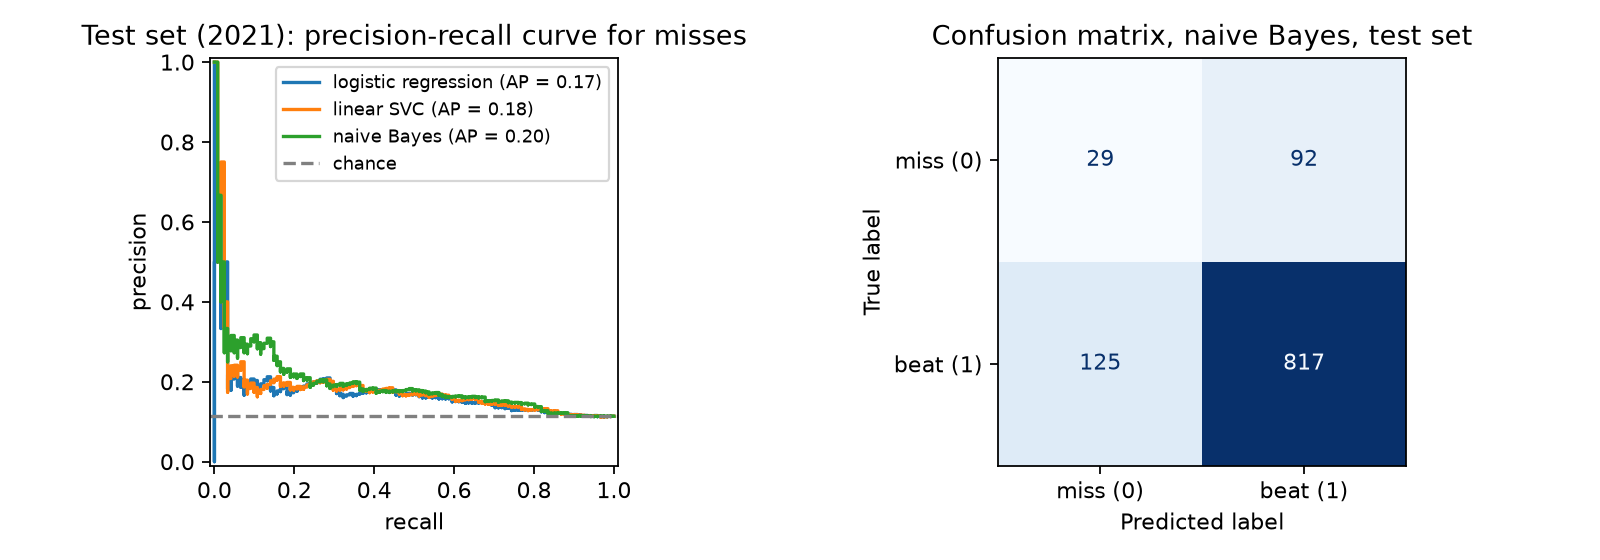

In [21]:
best_finbert = finbert_table.val_ap_negative.idxmax()
final_models = ["majority-class baseline (always predicts beat)", "TF-IDF + logistic regression",
                "TF-IDF + linear SVC", "TF-IDF + naive Bayes", best_finbert]
final = pd.DataFrame(test_results).set_index("method").loc[final_models]
final_table = pd.DataFrame({
    "validation AP": final.val_ap_negative,
    "test AP": final.test_ap_negative,
    "test AUC": final.test_roc_auc,
    "macro-F1": final.test_macro_f1,
    "balanced accuracy": final.test_balanced_accuracy,
    "accuracy": final.test_accuracy,
    "precision": final.test_precision_negative,
    "recall": final.test_recall_negative,
    "TP (misses caught)": final.test_confusion_matrix.map(lambda m: m[0][0]),
    "FP (beats flagged)": final.test_confusion_matrix.map(lambda m: m[1][0]),
})
print("Validation-set winner: %s (best FinBERT variant: %s)" % (winner_name, best_finbert))
print("95%% confidence interval for its macro-F1 gain over the baseline: [%+.3f, %+.3f]" % tuple(gain_ci))
display(final_table)
display(Image(filename=str(RESULTS_DIR / "fig_test.png")))

## 10. Summary

- **The words in an earnings call predict next-quarter EPS surprises better than chance, but only a little.** The model chosen on the validation set, naive Bayes on unigrams from the raw transcript, reaches test-set AP 0.197 against 0.114 for chance and macro-F1 0.547 against 0.470 for the majority-class baseline. It catches about a quarter of the misses.
- **Text processing did not matter.** All 20 setups land within about one bootstrap standard deviation of each other on the validation set.
- **FinBERT did not beat TF-IDF.** Its sentiment features were no better than chance under either chunking method. Its embeddings matched TF-IDF but did not beat it, and the two chunking methods could not be told apart.
- **The models mostly recognize industries.** The top features and the most confident mistakes are company and sector names, and removing names does not remove the signal because sector vocabulary remains.